# Ceasul Cuantic al Iașului
## Nivelul 5 — Ascunzătoarea

> ### Ora 13:00
>
> Ghicitoarea descifrată spune unde e cheia de repornire, dar în limbajul biților. Fiecare dintre cele opt locuri ale Iașului are un cod de 3 biți.
>
> Ați putea să le verificați pe rând. Dar Umbra mută cheia dacă stați prea mult.
>
> Un calculator cuantic caută altfel: cu **algoritmul lui Grover**, „întreabă” toate locurile deodată și amplifică răspunsul corect.

### Ce veți învăța în acest nivel

- ce este un **oracol** cuantic și cum „marchează” răspunsul cu un semn minus;
- cum **difuzorul** lui Grover amplifică răspunsul marcat (inversarea față de medie);
- de ce există un **număr optim de pași** și de ce prea mulți strică rezultatul.

In [1]:
# Rulați această celulă prima. Ea încarcă Qiskit și uneltele provocării.
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from ceas_cuantic import *

ECHIPA = "Don't quit, qubit!"   # COMPLETEAZĂ AICI — același nume în toate notebook-urile
COD_ECHIPA = "UP2U-JRC"     # COMPLETEAZĂ AICI — codul primit de la organizatori
start(ECHIPA, COD_ECHIPA)

Bine ați venit, echipa „Don't quit, qubit!”! Sunteți conectați la serverul provocării.


In [2]:
for cod, loc in LOCATII.items():
    print(f"{cod}  (B2={cod[0]}, B1={cod[1]}, B0={cod[2]})  →  {loc}")

000  (B2=0, B1=0, B0=0)  →  Palatul Culturii
001  (B2=0, B1=0, B0=1)  →  Teatrul Național
010  (B2=0, B1=1, B0=0)  →  Teiul lui Eminescu
011  (B2=0, B1=1, B0=1)  →  Biblioteca Centrală Universitară
100  (B2=1, B1=0, B0=0)  →  Grădina Botanică
101  (B2=1, B1=0, B0=1)  →  Turnul Goliei
110  (B2=1, B1=1, B0=0)  →  Mitropolia
111  (B2=1, B1=1, B0=1)  →  Campusul TUIASI


## 1. Ideea lui Grover

Pornim cu toate locurile în superpoziție egală (H pe toți qubiții). Apoi repetăm un **pas Grover**:

1. **Oracolul** înmulțește cu −1 amplitudinea locului căutat. La măsurare nu se vede nimic (probabilitatea depinde de pătrat), dar amplitudinea a „coborât” sub zero.
2. **Difuzorul** oglindește fiecare amplitudine față de **media** tuturor amplitudinilor. Locul marcat, aflat mult sub medie, ajunge mult deasupra.

Pentru $N$ locuri, Grover are nevoie de aproximativ $\frac{\pi}{4}\sqrt{N}$ pași, față de $N/2$ încercări în medie pentru o căutare clasică.

Urmăriți pașii pe 4 locuri (2 qubiți), cu oracolul pentru locul „11”. Oracolul pentru „11” este simplu: poarta **CZ** pune semnul minus doar pe $|11\rangle$. Difuzorul vi-l dăm gata făcut: `difuzor(n)`.

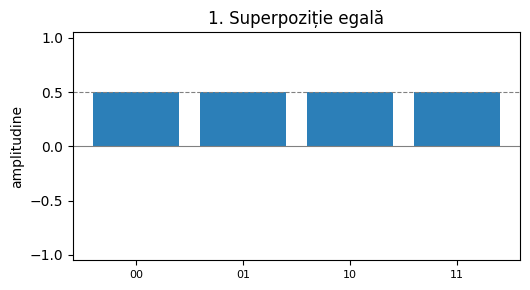

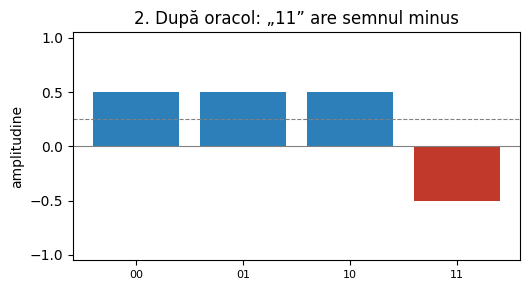

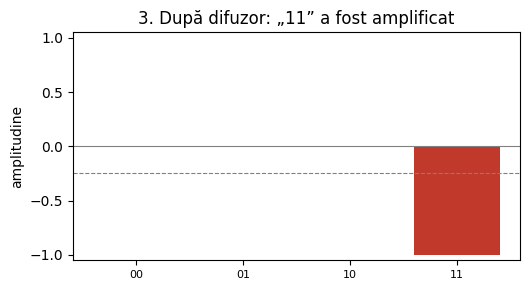

In [3]:
qc = QuantumCircuit(2)
qc.h([0, 1])
arata_amplitudini(qc, "1. Superpoziție egală")

qc.cz(0, 1)                                   # oracolul pentru „11”
arata_amplitudini(qc, "2. După oracol: „11” are semnul minus")

qc.compose(difuzor(2), inplace=True)          # difuzorul
arata_amplitudini(qc, "3. După difuzor: „11” a fost amplificat")

<div class="alert alert-block alert-success">
<b>Sarcina 5A — Grover pe 4 locuri (100 de puncte)</b>

Scrieți oracolul care marchează locul <b>„10”</b> (qubitul 1 = 1, qubitul 0 = 0).<br>
Idee: CZ marchează doar „11”. Ce poartă puneți înainte și după CZ ca să marcheze „10”?
</div>

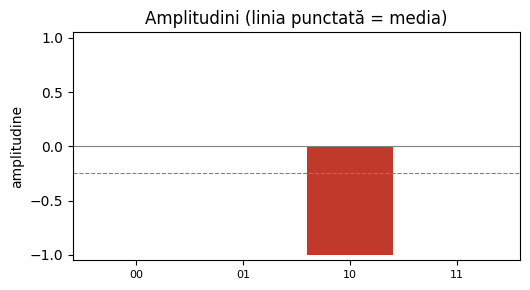

✔ Corect! Sarcina 5A — Grover pe 4 locuri: +100 puncte.


In [5]:
def oracol_4(qc):
    qc.x(0)
    qc.cz(0, 1)
    qc.x(0)
    return qc


grover_4 = QuantumCircuit(2)
grover_4.h([0, 1])
oracol_4(grover_4)
grover_4.compose(difuzor(2), inplace=True)
arata_amplitudini(grover_4)
verifica_5A(grover_4)

## 2. Opt locuri

Pe 3 qubiți vă dăm gata făcută funcția `marcheaza_111(qc)`: ea pune semnul minus doar pe $|111\rangle$ (este „CZ cu trei qubiți”, construită din H și poarta Toffoli). Rulați celula de mai jos ca s-o vedeți în acțiune.

Ca să marcați alt loc, folosiți același truc ca la sarcina 5A: întoarceți cu X qubiții care trebuie să fie **0**, aplicați `marcheaza_111`, apoi întoarceți-i înapoi.

Ghicitoarea de la nivelul 4 descrie locul căutat ca o formulă logică cu biții B2, B1, B0 (B0 este qubitul 0). O vom transforma intr-un oracol.

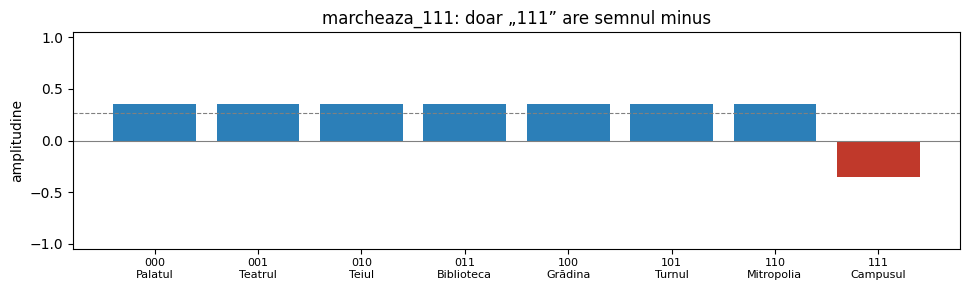

In [6]:
qc = QuantumCircuit(3)
qc.h(range(3))
marcheaza_111(qc)
arata_amplitudini(qc, "marcheaza_111: doar „111” are semnul minus")

<div class="alert alert-block alert-success">
<b>Sarcina 5B — Ascunzătoarea (150 de puncte · clopotul 6)</b>

<ol>
<li>Din ghicitoare, aflați codul locului (<code>tinta</code>) și scrieți <code>oracol_8(qc)</code>, care pune semnul minus doar pe acel loc.</li>
<li>Completați <code>grover_8(k)</code>: H pe toți cei 3 qubiți, apoi de k ori (oracol, difuzor).</li>
<li>Desenați probabilitatea locului căutat pentru k = 0…6 pași și alegeți numărul optim de pași.</li>
<li>Numiți locul, folosind <code>LOCATII</code>.</li>
</ol>
</div>

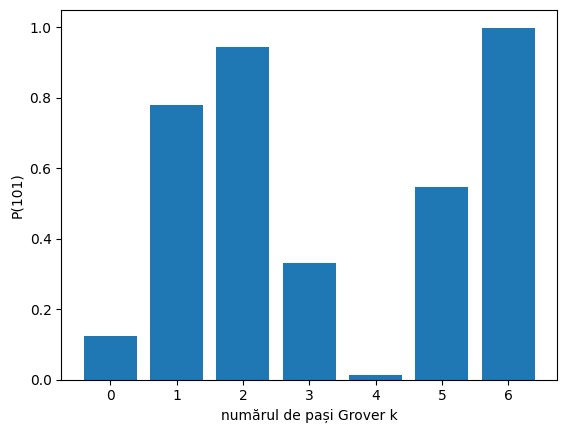

In [17]:
tinta = "101"   # COMPLETEAZĂ AICI: codul locului din ghicitoare (B2 B1 B0)


def oracol_8(qc):
    # COMPLETEAZĂ AICI
    qc.x(1)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)
    return qc


def grover_8(k):
    qc = QuantumCircuit(3)
    qc.h(range(3))
    for _ in range(k):
        oracol_8(qc)
        qc.compose(difuzor(3), inplace=True)
    return qc


pasi = list(range(7))
prob = [Statevector(grover_8(k)).probabilities_dict().get(tinta, 0) for k in pasi]
plt.bar(pasi, prob)
plt.xlabel("numărul de pași Grover k")
plt.ylabel(f"P({tinta})")
plt.show()

**Discutați:** graficul urcă și apoi coboară. Fiecare pas rotește starea cu același unghi $2\theta$, unde $\sin\theta = 1/\sqrt{8}$, iar $P = \sin^2\big((2k+1)\theta\big)$. Ce se întâmplă dacă „trecem” de țintă?

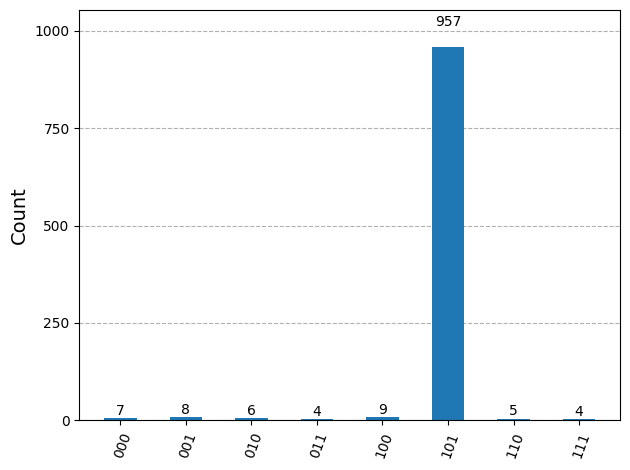

In [20]:
k_optim = 2     # COMPLETEAZĂ AICI
locatie = "Turnul Goliei"    # COMPLETEAZĂ AICI, de ex. LOCATII[tinta]
plot_histogram(masoara(grover_8(k_optim)))

In [21]:
verifica_5B(oracol_8, grover_8, k_optim, locatie)

✔ Corect! Sarcina 5B — Ascunzătoarea găsită: +150 puncte.
🔔 Clopotul 6 s-a aprins: Ascunzătoarea găsită.


<div class="alert alert-block alert-warning">
<b>Provocare extra — Două ascunzători (+50 de puncte)</b>

Umbra a făcut o copie a cheii. Noua formulă este <b>B2 SI B0</b>, adică două locuri.<br>
Construiți oracolul pentru această formulă, refaceți graficul și aflați numărul optim de pași. De ce s-a schimbat?
</div>

In [36]:
# COMPLETEAZĂ AICI: vedeti cum este construit oracolul si difuzorul la exercitiul anterior
# ...
# prob = [sum(...)]
# print(np.round(prob, 3))
def oracol(qc):
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)

def grover(k):
    qc = QuantumCircuit(3)
    qc.h(range(3))
    for _ in range(k):
        oracol(qc)
        qc.compose(difuzor(3), inplace=True)
    return qc

k_doua = 1
verifica_extra5(k_doua)

✔ Corect! Sarcina X5 — Extra: două soluții: +50 puncte.


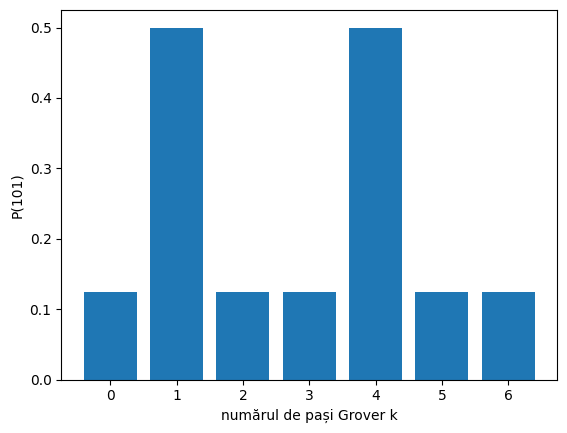

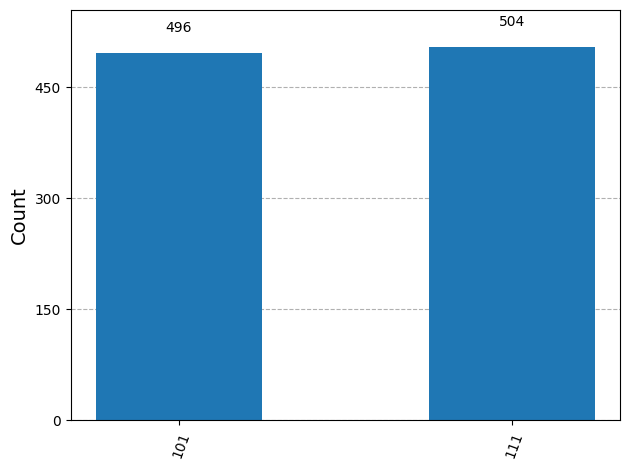

In [38]:
# COMPLETEAZĂ AICI: vedeti cum este construit oracolul si difuzorul la exercitiul anterior
# ...
tinta = "101"

def oracol(qc):
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(1)

def grover(k):
    qc = QuantumCircuit(3)
    qc.h(range(3))
    for _ in range(k):
        oracol(qc)
        qc.compose(difuzor(3), inplace=True)
    return qc

pasi = list(range(7))
prob = [Statevector(grover(k)).probabilities_dict().get(tinta, 0) for k in pasi]
plt.bar(pasi, prob)
plt.xlabel("numărul de pași Grover k")
plt.ylabel(f"P({tinta})")
plt.show()
# prob = [sum(...)]
# print(np.round(prob, 3))
k_doua = 1
plot_histogram(masoara(grover(k_doua)))

<div class="alert alert-block alert-info">
<b>La AC studiezi asta</b>

Căutarea, optimizarea și analiza complexității (cât de repede crește timpul de calcul) sunt în inima informaticii și a inteligenței artificiale pe care le studiați la AC.<br>
Grover arată că un calculator cuantic poate fi mai rapid, dar doar pentru anumite probleme și doar dacă algoritmul e construit atent.
</div>

> ### Ascunzătoarea
>
> Al șaselea clopot sună. Cheia de repornire era ascunsă în alt turn al Iașului. O aveți. Acum trebuie s-o folosiți pe un calculator cuantic adevărat.

## Sfârșitul nivelului 5

Rulați celula de mai jos ca să vedeți turnul echipei.

Când sunteți gata, deschideți **Nivelul_6_Clopotele.ipynb**.

In [ ]:
turn()